![The Same Function in LangSmith](assets/banner-03.svg)

**LangSmith** is the observability tool from the team behind LangChain. It is a hosted website, so there is nothing to install: you create a free account and get an API key.

We do exactly what we did in Langfuse:

1. Trace the simple **weather assistant**.
2. Trace the **travel agent** that chooses between three tools.

You will see that the code changes are almost identical. Once you understand traces and spans, every tool feels familiar.

## Step 1: Get a key and connect

1. Sign up at [smith.langchain.com](https://smith.langchain.com)
2. Open **Settings, API Keys** and create a key
3. Add these lines to the `.env` file, then restart this notebook's kernel:

```bash
LANGSMITH_TRACING=true
LANGSMITH_API_KEY=lsv2_...
LANGSMITH_PROJECT=weather-assistant
```

| Setting | What it does |
|---|---|
| `LANGSMITH_TRACING=true` | Switches tracing on. Without it nothing is sent |
| `LANGSMITH_API_KEY` | Proves the traces are yours |
| `LANGSMITH_PROJECT` | The folder your traces go into (created automatically) |

Newer LangSmith workspaces can also group traces by **agent** instead of project, with `LANGSMITH_AGENT_ID` and `LANGSMITH_AGENT_ENVIRONMENT`. Either works; the cell below tells you which one is active.

In [1]:
import os
import warnings

from dotenv import load_dotenv

warnings.filterwarnings("ignore")  # hide library notices so the output stays readable

load_dotenv("../.env")

from langsmith import Client

ls_client = Client()
print("Tracing on:     ", os.getenv("LANGSMITH_TRACING"))
print("API key present:", bool(os.getenv("LANGSMITH_API_KEY")))
if os.getenv("LANGSMITH_AGENT_ID"):
    print("Traces grouped by agent, environment:", os.getenv("LANGSMITH_AGENT_ENVIRONMENT"))
else:
    print("Traces go to project:", os.getenv("LANGSMITH_PROJECT", "default"))

Tracing on:      true
API key present: True
Traces grouped by agent, environment: local


## Step 2: Add LangSmith to the weather assistant

Same assistant as notebooks 01 and 02. Two changes, marked `# NEW`:

| Purpose | Langfuse | LangSmith |
|---|---|---|
| Record every AI call | `from langfuse.openai import OpenAI` | `client = wrap_openai(OpenAI())` |
| Turn a function into a span | `@observe()` | `@traceable` |

In [2]:
import time

from langsmith import traceable
from langsmith.wrappers import wrap_openai
from openai import OpenAI

client = wrap_openai(OpenAI())  # NEW: records every AI call

FAKE_WEATHER = {"Paris": "rainy, 14°C", "Tokyo": "sunny, 21°C", "London": "stormy, 11°C", "Dubai": "hot and dry, 35°C"}


@traceable  # NEW: this function becomes a span
def get_weather(city):
    time.sleep(0.5)
    return FAKE_WEATHER[city]


@traceable  # NEW
def ask_ai(question):
    reply = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": question}],
    )
    return reply.choices[0].message.content


@traceable  # NEW: the outer function becomes the whole trace
def weather_assistant(city):
    weather = get_weather(city)
    question = f"The weather in {city} is {weather}. Should I carry an umbrella? Answer in one short sentence."
    return ask_ai(question)

## Step 3: Run it

We give the run an id (`run_id`) so we can look it up afterwards. In normal use you do not need this; LangSmith creates ids on its own.

In [3]:
from langsmith import uuid7

run_id = uuid7()
print(weather_assistant("Paris", langsmith_extra={"run_id": run_id}))
ls_client.flush()  # send now (important in notebooks and short scripts)

Yes, you should carry an umbrella.


## Step 4: Check that the trace arrived

We read the trace back from LangSmith and draw it. If this works, tracing is set up correctly.

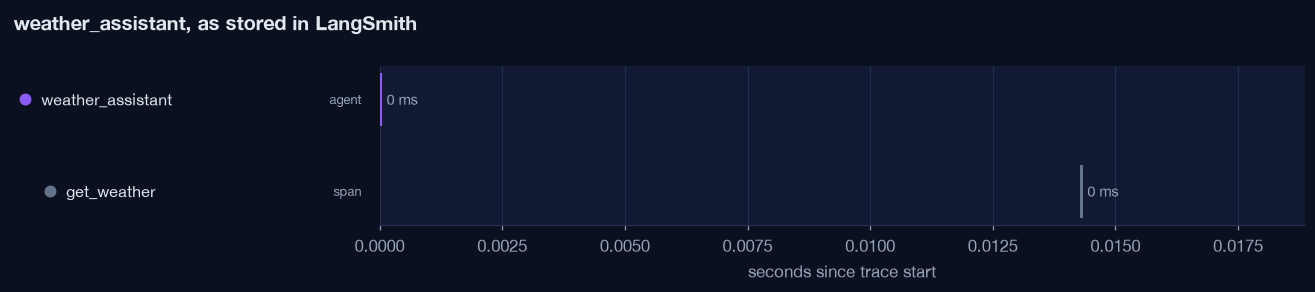

Project: mytest-local
Open in LangSmith: https://smith.langchain.com/o/0a76eedf-d570-4baf-a307-1df08fe1f0b8/projects/p/01a15c13-627d-7be5-833c-f9def2b6ceb4/r/01a15c18-e026-70e8-a9c5-e0ad853b029a?poll=true


In [4]:
import lab

root = lab.show_langsmith_trace(run_id, "weather_assistant, as stored in LangSmith")
print("Project:", ls_client.read_project(project_id=root.session_id).name)
print("Open in LangSmith:", ls_client.get_run_url(run=root))

The same tree as in Langfuse. The row LangSmith added for us is **`ChatOpenAI`**: the AI call recorded by `wrap_openai`, with tokens and cost.

In the LangSmith website: open **Tracing**, pick your project, click the newest `weather_assistant` row, then click each step in the tree on the left.

---

## Step 5: Trace the travel agent

Now the agent from notebook 02: the model decides which of three tools to call. The tools and the loop are the same code; only the decorators change.

| | Langfuse | LangSmith |
|---|---|---|
| A tool | `@observe(as_type="tool")` | `@traceable(run_type="tool")` |
| The agent | `@observe(as_type="agent")` | `@traceable(name="travel_agent")` |

In [5]:
import json
from datetime import datetime
from zoneinfo import ZoneInfo

CITY_INFO = {
    "Paris": {"weather": "rainy, 14°C", "timezone": "Europe/Paris"},
    "Tokyo": {"weather": "sunny, 21°C", "timezone": "Asia/Tokyo"},
    "London": {"weather": "stormy, 11°C", "timezone": "Europe/London"},
    "Dubai": {"weather": "hot and dry, 35°C", "timezone": "Asia/Dubai"},
}
RATES_PER_USD = {"EUR": 0.92, "JPY": 151.0, "GBP": 0.79, "AED": 3.67}  # fixed demo rates


@traceable(run_type="tool")
def get_weather_tool(city):
    time.sleep(0.3)
    return {"city": city, "weather": CITY_INFO[city]["weather"]}


@traceable(run_type="tool")
def get_local_time(city):
    now = datetime.now(ZoneInfo(CITY_INFO[city]["timezone"]))
    return {"city": city, "local_time": now.strftime("%H:%M")}


@traceable(run_type="tool")
def convert_currency(amount_usd, currency):
    return {"amount_usd": amount_usd, "currency": currency, "converted": round(amount_usd * RATES_PER_USD[currency], 2)}


def tool_schema(name, description, properties):
    return {
        "type": "function",
        "function": {
            "name": name,
            "description": description,
            "parameters": {"type": "object", "properties": properties, "required": list(properties)},
        },
    }


TOOLS = [
    tool_schema("get_weather", "Get today's weather for a city", {"city": {"type": "string", "enum": list(CITY_INFO)}}),
    tool_schema("get_local_time", "Get the current local time in a city", {"city": {"type": "string", "enum": list(CITY_INFO)}}),
    tool_schema(
        "convert_currency",
        "Convert US dollars to another currency",
        {"amount_usd": {"type": "number"}, "currency": {"type": "string", "enum": list(RATES_PER_USD)}},
    ),
]
RUN_TOOL = {"get_weather": get_weather_tool, "get_local_time": get_local_time, "convert_currency": convert_currency}


@traceable(name="travel_agent")
def travel_agent(question):
    messages = [
        {"role": "system", "content": "You are a travel assistant. Use the tools to answer. Reply in two short sentences."},
        {"role": "user", "content": question},
    ]
    for step in range(5):  # safety limit
        reply = client.chat.completions.create(model="gpt-4o-mini", messages=messages, tools=TOOLS)
        message = reply.choices[0].message

        if not message.tool_calls:  # final answer
            return message.content

        messages.append(message)
        for call in message.tool_calls:
            arguments = json.loads(call.function.arguments)
            result = RUN_TOOL[call.function.name](**arguments)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": json.dumps(result)})

    return "Sorry, I could not finish."

### Run the agent

In [6]:
agent_run_id = uuid7()
answer = travel_agent(
    "I land in London with 150 dollars. What's the weather, what time is it there, and how many pounds is that?",
    langsmith_extra={"run_id": agent_run_id, "metadata": {"user_id": "ana@example.com"}, "tags": ["agent"]},
)
print(answer)
ls_client.flush()

The weather in London is stormy with a temperature of 11°C. It's currently 02:35 AM there, and your $150 converts to approximately £118.50.


### What the agent did, step by step

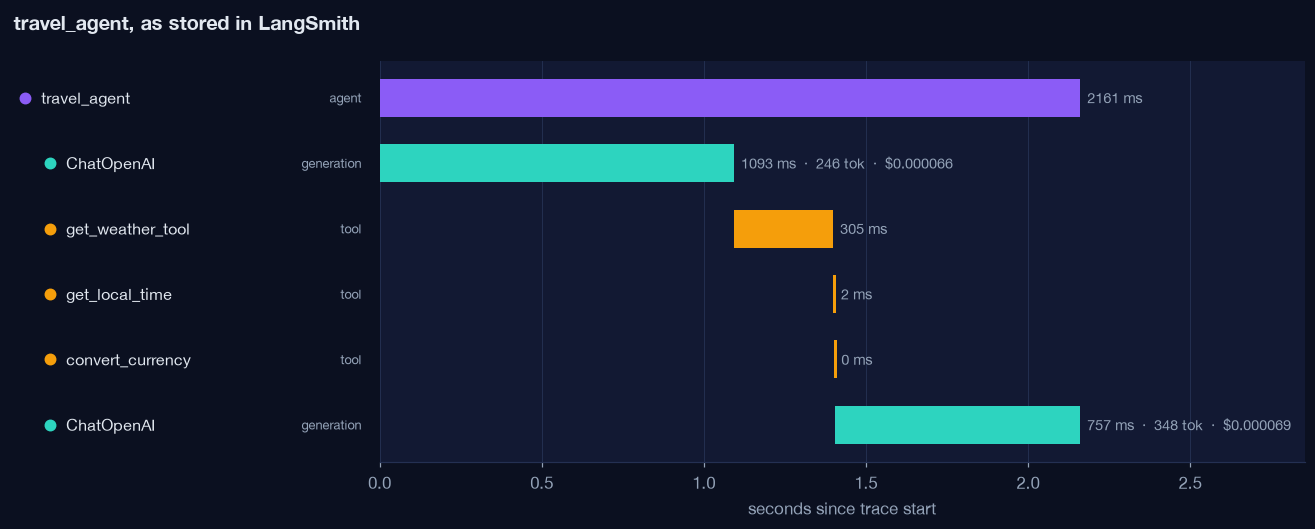

Open in LangSmith: https://smith.langchain.com/o/0a76eedf-d570-4baf-a307-1df08fe1f0b8/projects/p/01a15c13-627d-7be5-833c-f9def2b6ceb4/r/01a15c18-ed8e-738f-bd2a-9c22775133f1?poll=true


In [7]:
agent_root = lab.show_langsmith_trace(agent_run_id, "travel_agent, as stored in LangSmith")
print("Open in LangSmith:", ls_client.get_run_url(run=agent_root))

Same story as in Langfuse: the first `ChatOpenAI` call decides which tools to use, the tools run, and the second `ChatOpenAI` call writes the answer.

In the LangSmith website, click the first `ChatOpenAI` step and open its **output**: the tool calls the model asked for are listed with their arguments.

In [8]:
frame = lab.langsmith_frame(agent_root)
print("AI calls:   ", (frame["kind"] == "generation").sum())
print("Tool calls: ", (frame["kind"] == "tool").sum())
print("Tokens:     ", agent_root.total_tokens)
print("Cost:       $", round(float(agent_root.total_cost or 0), 6))
print("Total time: ", round(frame.loc[frame["depth"] == 0, "duration"].iloc[0], 2), "s")

AI calls:    2
Tool calls:  3
Tokens:      594
Cost:       $ 0.000135
Total time:  2.16 s


## Same ideas, different words

| What it is | OpenTelemetry | Langfuse | LangSmith |
|---|---|---|---|
| One request, start to finish | Trace | Trace | Trace |
| One step | Span | Observation | Run |
| An AI model call | Span with `gen_ai` details | Generation | LLM run (`ChatOpenAI`) |
| A folder of traces | Service | Project | Project (or Agent) |
| A conversation of many requests | | Session | Thread |

## Langfuse or LangSmith?

| | Langfuse | LangSmith |
|---|---|---|
| Price and license | Free and open source | Free tier, paid plans |
| Where it runs | Your laptop or server, or their cloud | Their cloud |
| Best when | You want control of your data | You already use LangChain or LangGraph |

Both are good choices. Pick the one your team will actually open every day.

**Next:** [04 Other tools](04_other_tools.ipynb). These two are not the only options.